---
title: "Transformers"
execute:
  enabled: false
format:
  html:
    code-fold: true
    code-summary: "Show the code"
---

![](images/under-construction.png){width=20%}

This notebook continues from the backpropagation notebook. There we built a network that reads a fixed-size image and outputs one of ten classes. Here we build a network that reads a *sequence* of characters and predicts the next one, which is what a language model is. The plan:

1. **Text as numbers.** Characters become integers; a model of text becomes "predict the next integer". The simplest such model, counting pairs, gives us a baseline.
2. **Attention.** The one new idea. A learned weighted average over earlier positions, written in NumPy in a handful of lines, with everything else borrowed from the digits network.
3. **A whole GPT forward pass in NumPy.** Embeddings, attention, a feed-forward layer, repeated a few times. With random weights it produces gibberish, which proves the plumbing works.
4. **Autograd.** We stop writing backward passes by hand. A library does the chain rule for us, and we check that it gets the same gradients we computed ourselves for the digits network.
5. **Training the GPT** on a text, on a laptop CPU, in a few minutes, and watching the gibberish turn into something that looks like language.

Solution cells are tagged `solution` as before.

In [1]:
import math, time, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 3.5)
np.random.seed(0)

## Part 1: Text as numbers

### Background

A digit classifier takes 64 numbers and outputs a probability for each of 10 classes. A character-level language model takes the last *n* characters and outputs a probability for each possible next character. Same shape of problem: an input vector in, a softmax over classes out, cross-entropy loss, "output minus target" gradient. The only differences are what the input is and how it gets turned into a vector.

### The data

We use a 1 MB file of Shakespeare that is a standard test text for small language models. Any plain-text file of a few hundred kilobytes or more works; a collection of Andersen's fairy tales in Danish is a natural choice for a Danish classroom and is one of the exercises.

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(url, "input.txt")
text = open("input.txt", encoding="utf-8").read()
print(len(text), "characters\n")
print(text[:300])

1115394 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


### Characters become integers

The vocabulary is simply every distinct character in the file. `encode` turns a string into a list of integers, `decode` turns it back. Nothing is learned here; this is bookkeeping.

In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)

print("vocabulary:", repr("".join(chars)))
print("size:", vocab_size)
print(encode("To be"), "->", decode(encode("To be")))

data = np.array(encode(text), dtype=np.int64)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]

vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
size: 65
[32, 53, 1, 40, 43] -> To be


### A baseline: the bigram model

Before any neural network, here is the simplest possible model of text: count how often each character is followed by each other character. The row for `q` will be almost entirely `u`. To generate text, start with a character, look up its row, draw the next character from those frequencies, repeat.

This matters as a *baseline*. Every model later must beat it, and we can say by how much.

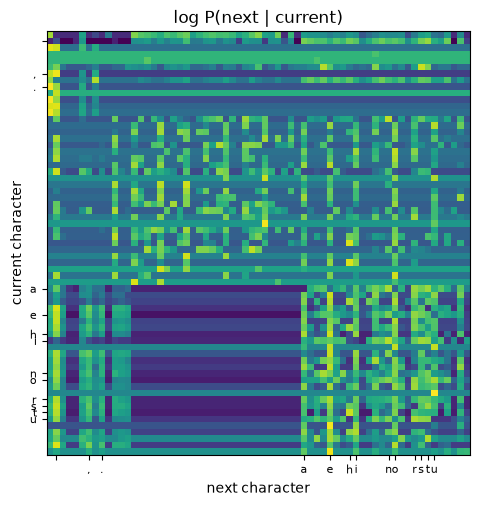


O:

Tormetl
V:

Whan ashe:ayarin se!
Wine, ges o tilo g is LI ar; by arththelyoounerdent stt two; tle tr, it sh s
Ths t gethalof finor:
Thuliou, w ter h pent t hedve!
Windy busitroue rl!
Whe me y,
Turais nfu mod RTENooust V: oobomooro n'sexayoourit te,-nd t squis hee h
So, twndwrerthot, n h lear wis


In [4]:
counts = np.zeros((vocab_size, vocab_size))
np.add.at(counts, (train_data[:-1], train_data[1:]), 1)      # counts[a, b] = times a was followed by b
bigram_P = (counts + 1) / (counts + 1).sum(axis=1, keepdims=True)   # +1 so that nothing has probability 0

plt.figure(figsize=(6, 5.5))
plt.imshow(np.log(bigram_P), cmap="viridis")
ticks = [stoi[c] for c in " .,aeiouhnrst"]
plt.xticks(ticks, [repr(itos[i])[1:-1] for i in ticks], fontsize=8); plt.yticks(ticks, [repr(itos[i])[1:-1] for i in ticks], fontsize=8)
plt.xlabel("next character"); plt.ylabel("current character"); plt.title("log P(next | current)"); plt.show()

def sample_bigram(n=300, seed=0):
    rng = np.random.default_rng(seed)
    out = [stoi["\n"]]
    for _ in range(n):
        out.append(rng.choice(vocab_size, p=bigram_P[out[-1]]))
    return decode(out)
print(sample_bigram())

It knows that `q` is followed by `u` and that lines end in newlines, and nothing else. Its average cross-entropy on held-out text is the number to beat:

In [5]:
bigram_loss = -np.log(bigram_P[val_data[:-1], val_data[1:]]).mean()
print(f"bigram cross-entropy on validation text: {bigram_loss:.3f} nats per character")
print(f"(a model that guesses uniformly would score {np.log(vocab_size):.3f})")

bigram cross-entropy on validation text: 2.482 nats per character
(a model that guesses uniformly would score 4.174)


**Exercise 1.1.** Build a *trigram* model: count triples and condition on the last two characters. (Use a `vocab_size × vocab_size × vocab_size` array; it is only 65³ ≈ 275 000 entries.) Sample from it and compute its validation cross-entropy. Why can't this approach be pushed much further, say to 10 characters of context?

In [6]:
# Solution 1.1
counts3 = np.zeros((vocab_size, vocab_size, vocab_size))
np.add.at(counts3, (train_data[:-2], train_data[1:-1], train_data[2:]), 1)
# Smoothing: most of the 65^3 contexts are never seen. Instead of adding 1 to every
# cell (which makes unseen contexts uniform and generates garbage), add the bigram
# distribution for the last character: "if you have no idea, fall back to bigrams".
P3 = (counts3 + bigram_P[None, :, :]) / (counts3.sum(axis=2, keepdims=True) + 1)
trigram_loss = -np.log(P3[val_data[:-2], val_data[1:-1], val_data[2:]]).mean()
print(f"trigram validation cross-entropy: {trigram_loss:.3f}  (bigram was {bigram_loss:.3f})")

rng = np.random.default_rng(0); out = encode("\nT")
for _ in range(300):
    out.append(rng.choice(vocab_size, p=P3[out[-2], out[-1]]))
print(decode(out))
# A table over k characters of context has 65**k entries: 65**10 is about 10**18.
# Almost all of those contexts never occur in the training text, so there is
# nothing to count. A neural network replaces the table with a function that
# can generalise between contexts it has never seen in exactly that form.

trigram validation cross-entropy: 2.061  (bigram was 2.482)

Thad
crounto
rat the Pason.' the brients not it pathave belf
That ses,
Stay istripent?
At tor try woul: wello; ked
Why the wilet aingen, thy mot it thich reiver heave frot youstestis bromerech, My Apried,
Pit my hat ithous a the reir? Clauly wishent theyes; I to the ne.
'Tishrootlest. This hat is wit


## Part 2: Attention

### Background

A network that predicts the next character needs to look at the previous ones. The digits network can't: it takes a fixed-size vector. We could concatenate the last *n* character vectors into one long vector, but then the weights connected to "the character 3 positions back" are entirely separate from those for "4 positions back", and the model has to learn every pattern separately at every offset. It is the shifted-digits problem again.

**Attention** solves this. Each position produces a new vector that is a **weighted average of the vectors at earlier positions**, where the weights depend on content rather than offset. "Look at the most recent vowel" or "look at the last space" are things a weighted average can express, at any distance.

### Step 1: average everything before you

Let the input be a sequence of $n$ vectors, one per character, as the rows of a matrix $X$ ($n \times d$). The crudest form of "looking back" is to replace each row by the average of itself and all previous rows. That is a matrix product $A X$ where $A$ is lower-triangular with equal weights in each row.

[[1.   0.   0.   0.   0.  ]
 [0.5  0.5  0.   0.   0.  ]
 [0.33 0.33 0.33 0.   0.  ]
 [0.25 0.25 0.25 0.25 0.  ]
 [0.2  0.2  0.2  0.2  0.2 ]]


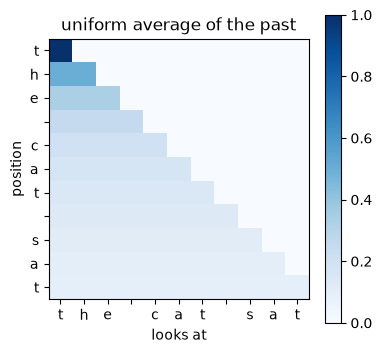

In [7]:
def softmax(z, axis=-1):
    e = np.exp(z - z.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)

sentence = "the cat sat"
n = len(sentence)
d = 8
rng = np.random.default_rng(0)
E = rng.normal(size=(vocab_size, d))         # a random vector for every character in the vocabulary
X = E[encode(sentence)]                     # one row per character of our sentence:  n x d

A_uniform = np.tril(np.ones((n, n)))
A_uniform /= A_uniform.sum(axis=1, keepdims=True)
print(np.round(A_uniform[:5, :5], 2))

def show_attention(A, title):
    plt.figure(figsize=(4.2, 4))
    plt.imshow(A, cmap="Blues", vmin=0, vmax=1)
    plt.xticks(range(n), list(sentence)); plt.yticks(range(n), list(sentence))
    plt.xlabel("looks at"); plt.ylabel("position"); plt.title(title); plt.colorbar(); plt.show()
show_attention(A_uniform, "uniform average of the past")

Row $i$ of $A$ says how much position $i$ looks at each other position; the rows sum to 1. The zeros above the diagonal are the **causal mask**: position $i$ may not look at anything after it, because at generation time the future does not exist yet.

### Step 2: let the weights depend on content

Instead of equal weights, each position should decide for itself which earlier positions matter. The mechanism:

- Every position emits a **query** vector $q_i = x_i W_q$: "what am I looking for?"
- Every position emits a **key** vector $k_j = x_j W_k$: "what do I contain?"
- The score for position $i$ looking at position $j$ is the dot product $q_i \cdot k_j$: high when the query matches the key.
- Scores above the diagonal are set to $-\infty$ (the mask), and a softmax over each row turns the scores into weights that sum to 1.
- Every position also emits a **value** vector $v_j = x_j W_v$, and the output is the weighted average of the values.

The division by $\sqrt{d_k}$ keeps the scores at a sensible scale so the softmax does not saturate. $W_q, W_k, W_v$ are the only learnable weights, and they are ordinary matrices like $W_1$ in the digits network.

output shape: (11, 8)


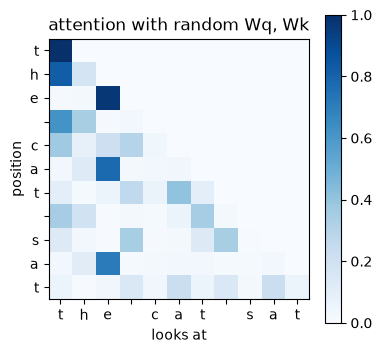

In [8]:
def attention(X, Wq, Wk, Wv, return_A=False):
    "Causal self-attention for one sequence X (n x d). Returns the new vectors (n x dv)."
    n = X.shape[0]
    Q, K, V = X @ Wq, X @ Wk, X @ Wv                 # three linear layers
    scores = Q @ K.T / np.sqrt(Wk.shape[1])          # n x n: how much i matches j
    mask = np.triu(np.ones((n, n), dtype=bool), 1)   # True above the diagonal = the future
    scores = np.where(mask, -np.inf, scores)
    A = softmax(scores, axis=1)                      # each row sums to 1
    out = A @ V                                      # weighted average of values
    return (out, A) if return_A else out

dk = 8
Wq, Wk, Wv = (rng.normal(size=(d, dk)) * 0.5 for _ in range(3))
out, A = attention(X, Wq, Wk, Wv, return_A=True)
print("output shape:", out.shape)
show_attention(A, "attention with random Wq, Wk")

With random weights the pattern is arbitrary, but notice its properties: rows sum to 1, nothing above the diagonal, and the weights differ between positions because the characters differ. Training will shape $W_q$ and $W_k$ so that useful pairs get high scores.

**Exercise 2.1.** Hand-design $W_q$ and $W_k$ so that every position attends mostly to the most recent space character (which marks a word boundary). Hint: you control the character vectors `E` too; give the space character a distinctive direction.

**Exercise 2.2.** Remove the mask and look at the attention matrix. For predicting the next character, why would the unmasked version be cheating?

**Exercise 2.3.** Real transformers use several attention "heads" in parallel, each with its own small $W_q, W_k, W_v$, and concatenate their outputs. Implement `multihead(X, list_of_weight_triples)`. Why might two heads be better than one head of twice the size?

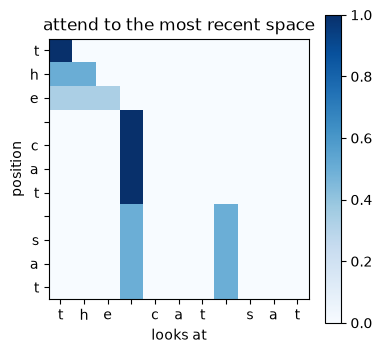

In [9]:
# Solution 2.1
E2 = np.zeros((vocab_size, d)); E2[:, 0] = 1.0        # every character: a 1 in slot 0 ...
E2[stoi[" "], 1] = 1.0                                # ... and the space also has a 1 in slot 1
X2 = E2[encode(sentence)]
Wq2 = np.zeros((d, dk)); Wq2[0, 0] = 5.0              # every query points along slot 0 of the key space
Wk2 = np.zeros((d, dk)); Wk2[1, 0] = 5.0              # only the space character produces a key there
_, A2 = attention(X2, Wq2, Wk2, np.eye(d), return_A=True)
show_attention(A2, "attend to the most recent space")
# Positions before the first space have nothing to match, so all scores are equal
# and they fall back to a uniform average. After the first space, the spaces win the
# softmax. But both spaces get the same score, so from "sat" onwards attention is
# split between them: with content alone there is no way to prefer the *most recent*
# space. That needs position information, which is Part 3's positional embedding.

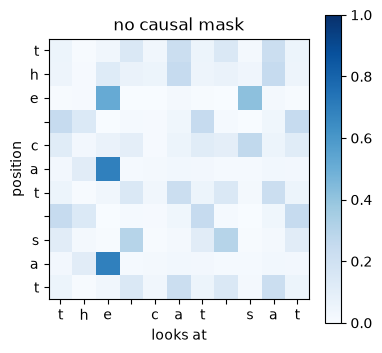

In [10]:
# Solution 2.2
scores = (X @ Wq) @ (X @ Wk).T / np.sqrt(dk)
A_nomask = softmax(scores, axis=1)
show_attention(A_nomask, "no causal mask")
# Without the mask, the vector at position i is computed using characters after i,
# including the very character the model is asked to predict at position i. The
# model would simply copy the answer during training and fail at generation time,
# when the future characters do not exist yet.

In [11]:
# Solution 2.3
def multihead(X, heads):
    return np.concatenate([attention(X, Wq, Wk, Wv) for Wq, Wk, Wv in heads], axis=1)
heads = [tuple(rng.normal(size=(d, 4)) * 0.5 for _ in range(3)) for _ in range(2)]
print("two heads of width 4 ->", multihead(X, heads).shape)
# One head produces ONE weighting of the past per position. Two heads can look at
# two different things at once (say, the previous character and the last vowel) and
# hand both to the next layer. A single wider head still has only one softmax row.

two heads of width 4 -> (11, 8)


## Part 3: A whole GPT forward pass in NumPy

### Background

A GPT is attention plus pieces we already know, stacked. For an input of $n$ character ids:

1. **Token embedding.** Look up a learned vector for each character: `tok_emb[ids]`. (Equivalent to multiplying a one-hot vector by a matrix, i.e. a linear layer.)
2. **Position embedding.** Add a learned vector for each *position* 0..n-1, so the model can tell "3 characters ago" from "7 characters ago". Attention alone is blind to order.
3. **Blocks**, repeated `n_layer` times. Each block is
   $$x \leftarrow x + \mathrm{Attention}(\mathrm{LayerNorm}(x)),\qquad x \leftarrow x + \mathrm{MLP}(\mathrm{LayerNorm}(x))$$
   The MLP is exactly the digits network: a linear layer, a non-linearity, a linear layer. The `x + ...` is a **residual connection**: each block adds a correction to $x$ instead of replacing it, which keeps gradients flowing through deep stacks. **LayerNorm** rescales each vector to mean 0 and variance 1, a stabiliser.
4. **Output head.** A final linear layer to `vocab_size` scores per position; softmax over those is the distribution for the next character.

That is the whole architecture. Modern models are this, scaled up, with a few refinements.

In [12]:
def layernorm(x, g, b, eps=1e-5):
    mu = x.mean(axis=-1, keepdims=True); var = x.var(axis=-1, keepdims=True)
    return (x - mu) / np.sqrt(var + eps) * g + b

def init_params(vocab_size, block_size, n_embd, n_head, n_layer, seed=0):
    rng = np.random.default_rng(seed); s = 0.02
    P = {"tok_emb": rng.normal(0, s, (vocab_size, n_embd)),
         "pos_emb": rng.normal(0, s, (block_size, n_embd)),
         "ln_f_g": np.ones(n_embd), "ln_f_b": np.zeros(n_embd),
         "head": rng.normal(0, s, (n_embd, vocab_size)), "blocks": []}
    for _ in range(n_layer):
        P["blocks"].append({
            "ln1_g": np.ones(n_embd), "ln1_b": np.zeros(n_embd),
            "Wq": rng.normal(0, s, (n_embd, n_embd)), "Wk": rng.normal(0, s, (n_embd, n_embd)),
            "Wv": rng.normal(0, s, (n_embd, n_embd)), "Wo": rng.normal(0, s, (n_embd, n_embd)),
            "ln2_g": np.ones(n_embd), "ln2_b": np.zeros(n_embd),
            "W1": rng.normal(0, s, (n_embd, 4*n_embd)), "b1": np.zeros(4*n_embd),
            "W2": rng.normal(0, s, (4*n_embd, n_embd)), "b2": np.zeros(n_embd)})
    P["n_head"] = n_head
    return P

def multihead_attention(x, blk, n_head):
    n, d = x.shape; hd = d // n_head
    Q, K, V = x @ blk["Wq"], x @ blk["Wk"], x @ blk["Wv"]
    heads = []
    for h in range(n_head):                                   # each head uses a slice of Q, K, V
        q, k, v = Q[:, h*hd:(h+1)*hd], K[:, h*hd:(h+1)*hd], V[:, h*hd:(h+1)*hd]
        scores = q @ k.T / np.sqrt(hd)
        scores = np.where(np.triu(np.ones((n, n), dtype=bool), 1), -np.inf, scores)
        heads.append(softmax(scores, axis=1) @ v)
    return np.concatenate(heads, axis=1) @ blk["Wo"]           # mix the heads back together

def gpt_forward(P, ids):
    "ids: 1-D array of character ids (length <= block_size). Returns n x vocab_size scores."
    n = len(ids)
    x = P["tok_emb"][ids] + P["pos_emb"][:n]                   # what + where
    for blk in P["blocks"]:
        x = x + multihead_attention(layernorm(x, blk["ln1_g"], blk["ln1_b"]), blk, P["n_head"])
        h = np.maximum(0, layernorm(x, blk["ln2_g"], blk["ln2_b"]) @ blk["W1"] + blk["b1"])   # the digits network
        x = x + h @ blk["W2"] + blk["b2"]
    return layernorm(x, P["ln_f_g"], P["ln_f_b"]) @ P["head"]

def count_params(P):
    total = sum(v.size for k, v in P.items() if isinstance(v, np.ndarray))
    return total + sum(v.size for blk in P["blocks"] for v in blk.values())

block_size, n_embd, n_head, n_layer = 64, 64, 4, 2
P = init_params(vocab_size, block_size, n_embd, n_head, n_layer)
print(f"{count_params(P):,} parameters")
ids = np.array(encode("To be, or not to be"))
logits = gpt_forward(P, ids)
print("input length", len(ids), "-> output", logits.shape, "(one score per vocabulary entry, per position)")

112,000 parameters
input length 19 -> output (19, 65) (one score per vocabulary entry, per position)


### Generating text

Generation is a loop: feed the characters so far, take the scores at the *last* position, softmax, draw a character, append, repeat. With random weights the result is noise, but it demonstrates that every shape lines up. The digits network needed the test images to prove it worked; here the plumbing check is simply "does it produce characters".

In [13]:
def generate(forward, ids, n_new, block_size, temperature=1.0, seed=0):
    rng = np.random.default_rng(seed); ids = list(ids)
    for _ in range(n_new):
        context = np.array(ids[-block_size:])
        p = softmax(forward(context)[-1] / temperature)
        ids.append(rng.choice(len(p), p=p))
    return ids

print(decode(generate(lambda c: gpt_forward(P, c), encode("\n"), 200, block_size)))


cF! oubiWvo
r!i;qWHO!.fdbMzygdgM.iVHSswLYJaJMsBc'plDr&J3QnC&NB,ZGfAwL,cuPxTObzwQkTVmOjgv-ivx ryx3ysoRCnvEWPv$ib h kUv&q&JOyXEDsB-FZXnXGNocxLXaq3Nu!oNp
K'eFgw.q&LOSylHErsVJzH;rnexvjqD3eh:NuYZ?VV,yY
lyZ


**Exercise 3.1.** What fraction of the parameters sit in the embeddings and output head versus in the blocks? How does this change if `n_layer` is 6?

**Exercise 3.2.** Build a model with `n_layer=1` and the position embedding replaced by zeros. Run `gpt_forward` on `"abc"` and `"bac"` and compare the outputs at the last position. Then do the same for `"abc"` and `"cba"`. Explain both results, and why they mean position information is necessary. (Harder: repeat with `n_layer=2`. Something changes; can you see why?)

In [14]:
# Solution 3.1
for nl in [2, 6]:
    P_ = init_params(vocab_size, block_size, n_embd, n_head, nl)
    emb = P_["tok_emb"].size + P_["pos_emb"].size + P_["head"].size
    print(f"n_layer={nl}: embeddings+head {emb:,}  blocks {count_params(P_)-emb:,}")
# With a tiny vocabulary of 65 the embeddings are cheap; the blocks dominate and
# grow linearly with depth. Models with word-piece vocabularies of 50 000 have
# much larger embedding tables.

n_layer=2: embeddings+head 12,416  blocks 99,584
n_layer=6: embeddings+head 12,416  blocks 298,496


In [15]:
# Solution 3.2
for nl in [1, 2]:
    P_ = init_params(vocab_size, block_size, n_embd, n_head, nl)
    P_nopos = {**P_, "pos_emb": np.zeros_like(P_["pos_emb"])}
    fwd = lambda t: gpt_forward(P_nopos, np.array(encode(t)))
    print(f"n_layer={nl}:  abc vs bac equal: {np.allclose(fwd('abc')[-1], fwd('bac')[-1])}"
          f"   abc vs cba equal: {np.allclose(fwd('abc')[-1], fwd('cba')[-1])}")
# One layer, no positions: attention is a weighted average over the SET of visible
# vectors, with weights that depend on content, not place. The last position of
# "abc" and "bac" is the same token (c) looking at the same set {a, b, c}, so the
# outputs are identical: the model cannot tell "ab" from "ba". For "cba" the last
# token itself differs, so the output differs, but not because of the order of the
# other two. A model that can't distinguish "dog bites man" from "man bites dog"
# is useless, hence the position embedding.
#
# With two layers the equality breaks: after layer 1, position 0 holds f({a}) in
# "abc" but f({b}) in "bac", because the causal mask gave each position a different
# set. Layer 2 then sees different inputs. So the mask leaks a little order
# information through depth, but it is weak and indirect; learned positions are
# the real fix.

n_layer=1:  abc vs bac equal: True   abc vs cba equal: False
n_layer=2:  abc vs bac equal: False   abc vs cba equal: False


## Part 4: Autograd, or why we stop writing backward passes

### Background

We have a forward pass with roughly a dozen distinct operations: embedding lookups, matrix products, softmax, masking, layer norm, ReLU, residual sums. To train it with the method from the first notebook we would have to derive the local derivative of each of these, chain them backwards through every block, and get all the transposes right. It is the same chain rule as before, with no new ideas. It is also several hundred lines of code in which every mistake is silent.

That is why nobody does it by hand any more. An **autograd** library records every operation during the forward pass and runs the chain rule backwards for you. PyTorch is the common choice. The code looks like NumPy with two additions: tensors that remember they need gradients, and one call, `loss.backward()`, that fills in `.grad` for every one of them.

### Checking the library against our own backprop

A good way to trust autograd is to make it reproduce a gradient we computed by hand. Here is the first notebook's one-weight example in PyTorch:

> **Note from the author:** the cells from here on need PyTorch (`pip install torch`). They are written but were not executed when this file was generated, because PyTorch could not be installed in the sandbox used to build the notebook. Run them locally; on a laptop CPU the training cell takes a few minutes.

In [17]:
import torch
torch.manual_seed(0)

x, t = 2.0, 7.0
w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

y = w*x + b
loss = (y - t)**2
loss.backward()                          # the chain rule, run for us
print("autograd:  dL/dw =", w.grad.item(), "  dL/db =", b.grad.item())
print("by hand :  dL/dw =", 2*(y.item()-t)*x, "  dL/db =", 2*(y.item()-t))

autograd:  dL/dw = -24.0   dL/db = -12.0
by hand :  dL/dw = -24.0   dL/db = -12.0


And the digits network, with our hand-written backward pass next to PyTorch's:

In [18]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd = digits.data[:32] / 16.0; yd = digits.target[:32]
Td = np.eye(10)[yd]
rng = np.random.default_rng(0)
W1 = rng.normal(0, 1/8, (64, 32)); b1 = np.zeros(32)
W2 = rng.normal(0, 1/np.sqrt(32), (32, 10)); b2 = np.zeros(10)

# --- by hand, exactly as in the first notebook ---
sigmoid = lambda z: 1/(1+np.exp(-z))
h = sigmoid(Xd @ W1 + b1); p = softmax(h @ W2 + b2)
dz2 = (p - Td) / 32
dW2 = h.T @ dz2; dz1 = (dz2 @ W2.T) * h * (1-h); dW1 = Xd.T @ dz1

# --- PyTorch ---
tW1, tb1, tW2, tb2 = (torch.tensor(a, requires_grad=True) for a in (W1, b1, W2, b2))
tX, ty = torch.tensor(Xd), torch.tensor(yd)
th = torch.sigmoid(tX @ tW1 + tb1)
logits = th @ tW2 + tb2
loss = torch.nn.functional.cross_entropy(logits, ty)   # softmax + cross-entropy, averaged over the batch
loss.backward()

print("max |difference| in dW1:", np.abs(tW1.grad.numpy() - dW1).max())
print("max |difference| in dW2:", np.abs(tW2.grad.numpy() - dW2).max())

max |difference| in dW1: 6.938893903907228e-18
max |difference| in dW2: 1.3877787807814457e-17


Agreement to around $10^{-17}$. The library is doing what we did, and from now on we let it.

**Exercise 4.1.** Make PyTorch compute the gradient of our NumPy `attention` function. Convert `X`, `Wq`, `Wk`, `Wv` to tensors with `requires_grad=True`, write the attention forward pass in torch (replace `np.` with `torch.`, `.T` stays `.T`, `np.where` becomes `torch.where`), take `out.sum()` as a scalar loss and call `.backward()`. Then check `Wq.grad` against a numerical "nudge" gradient on one entry, exactly as in Part 1 of the first notebook.

**Exercise 4.2 (stretch).** Derive the backward pass of single-head attention by hand and verify it against autograd. With $S = QK^\top/\sqrt{d_k}$, $A = \mathrm{softmax}(S)$ (row-wise) and $O = AV$, and an incoming gradient $G = \partial L/\partial O$:
$\partial L/\partial V = A^\top G$, $\;\partial L/\partial A = G V^\top$, $\;\partial L/\partial S = A \odot (\partial L/\partial A - \mathrm{rowsum}(\partial L/\partial A \odot A))$, $\;\partial L/\partial Q = (\partial L/\partial S)\, K/\sqrt{d_k}$, $\;\partial L/\partial K = (\partial L/\partial S)^\top Q/\sqrt{d_k}$.

In [19]:
# Solution 4.1
def attention_torch(X, Wq, Wk, Wv):
    n = X.shape[0]
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    scores = Q @ K.T / math.sqrt(Wk.shape[1])
    mask = torch.triu(torch.ones(n, n, dtype=torch.bool), 1)
    scores = torch.where(mask, torch.tensor(-float("inf"), dtype=scores.dtype), scores)
    return torch.softmax(scores, dim=1) @ V

tX, tWq, tWk, tWv = (torch.tensor(a, requires_grad=True) for a in (X, Wq, Wk, Wv))
attention_torch(tX, tWq, tWk, tWv).sum().backward()

h_ = 1e-6
Wq_plus = Wq.copy(); Wq_plus[0, 0] += h_
numerical = (attention(X, Wq_plus, Wk, Wv).sum() - attention(X, Wq, Wk, Wv).sum()) / h_
print(f"autograd dL/dWq[0,0] = {tWq.grad[0,0].item():.6f}   numerical = {numerical:.6f}")

autograd dL/dWq[0,0] = -1.411161   numerical = -1.411162


In [20]:
# Solution 4.2
n_, dk_ = X.shape[0], Wq.shape[1]
Q, K, V = X @ Wq, X @ Wk, X @ Wv
S = Q @ K.T / np.sqrt(dk_)
S = np.where(np.triu(np.ones((n_, n_), dtype=bool), 1), -np.inf, S)
A = softmax(S, axis=1); O = A @ V
G = np.ones_like(O)                                     # dL/dO for L = O.sum()
dV = A.T @ G
dA = G @ V.T
dS = A * (dA - (dA * A).sum(axis=1, keepdims=True))     # softmax backward, row by row
dQ = dS @ K / np.sqrt(dk_); dK = dS.T @ Q / np.sqrt(dk_)
dWq, dWk, dWv = X.T @ dQ, X.T @ dK, X.T @ dV
print("max |hand - autograd|  Wq:", np.abs(dWq - tWq.grad.numpy()).max(),
      " Wk:", np.abs(dWk - tWk.grad.numpy()).max(), " Wv:", np.abs(dWv - tWv.grad.numpy()).max())
# The masked entries have A = 0, so dS is 0 there automatically: the mask needs no
# special handling in the backward pass. This is one head of one layer with no
# layer norm, residuals or embeddings; multiply the bookkeeping accordingly to
# see why autograd exists.

max |hand - autograd|  Wq: 1.7763568394002505e-15  Wk: 1.3322676295501878e-15  Wv: 1.3322676295501878e-15


## Part 5: Training the GPT

### Background

Now we rewrite `gpt_forward` in PyTorch. Compare it line by line with the NumPy version: the same operations in the same order. The differences are that weights are wrapped so that autograd tracks them, and that we process a **batch** of sequences at once (one more leading dimension), which is what makes a CPU fast enough.

The training data is every window of `block_size` characters in the text, with the target being the same window shifted one character to the right. One window of 64 characters is therefore 64 training examples at once: predict character 2 from character 1, character 3 from characters 1–2, and so on. That is why the causal mask matters: position $i$ is trained to predict character $i+1$ without seeing it.

In [21]:
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(0)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        self.n_head = n_head
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.Wq, self.Wk, self.Wv, self.Wo = (nn.Linear(n_embd, n_embd, bias=False) for _ in range(4))
        self.W1, self.W2 = nn.Linear(n_embd, 4*n_embd), nn.Linear(4*n_embd, n_embd)

    def attention(self, x):
        B, n, d = x.shape; hd = d // self.n_head
        # same as the NumPy version, but all heads at once: (B, n, d) -> (B, n_head, n, hd)
        q = self.Wq(x).view(B, n, self.n_head, hd).transpose(1, 2)
        k = self.Wk(x).view(B, n, self.n_head, hd).transpose(1, 2)
        v = self.Wv(x).view(B, n, self.n_head, hd).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(hd)
        mask = torch.triu(torch.ones(n, n, dtype=torch.bool), 1)
        scores = scores.masked_fill(mask, float("-inf"))
        A = torch.softmax(scores, dim=-1)
        out = (A @ v).transpose(1, 2).reshape(B, n, d)         # concatenate the heads
        return self.Wo(out), A

    def forward(self, x):
        a, _ = self.attention(self.ln1(x))
        x = x + a
        x = x + self.W2(torch.relu(self.W1(self.ln2(x))))
        return x

class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.ModuleList([Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, ids):                                    # ids: (B, n) integers
        B, n = ids.shape
        x = self.tok_emb(ids) + self.pos_emb(torch.arange(n))  # what + where
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.ln_f(x))                         # (B, n, vocab_size)

    @torch.no_grad()
    def generate(self, ids, n_new, temperature=1.0):
        for _ in range(n_new):
            logits = self(ids[:, -self.block_size:])[:, -1] / temperature
            nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
            ids = torch.cat([ids, nxt], dim=1)
        return ids

model = GPT(vocab_size, block_size, n_embd, n_head, n_layer)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

112,065 parameters


In [22]:
train_t, val_t = torch.tensor(train_data), torch.tensor(val_data)

def get_batch(split, batch_size=32):
    d = train_t if split == "train" else val_t
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i+block_size] for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])   # the same window, shifted by one
    return x, y

@torch.no_grad()
def estimate_loss(split, n_batches=20):
    model.eval()
    losses = [F.cross_entropy(model(x).transpose(1, 2), y).item() for x, y in (get_batch(split) for _ in range(n_batches))]
    model.train()
    return float(np.mean(losses))

xb, yb = get_batch("train")
print("one batch:", xb.shape, "->", yb.shape)
print("first window :", repr(decode(xb[0][:30])))
print("its targets  :", repr(decode(yb[0][:30])))

one batch: torch.Size([32, 64]) -> torch.Size([32, 64])
first window : 'eir own kisses sin;\nBut Romeo '
its targets  : 'ir own kisses sin;\nBut Romeo m'


The training loop is the one from the first notebook with the backward pass replaced by `loss.backward()`, and the plain `w -= lr * grad` replaced by an optimiser (AdamW) that adapts the step size per weight. We print a sample every few hundred steps to watch it learn.

In [23]:
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
n_steps = 1500
history, t0 = [], time.time()

for step in range(n_steps + 1):
    if step % 250 == 0:
        tr, va = estimate_loss("train"), estimate_loss("val")
        history.append((step, tr, va))
        sample = decode(model.generate(torch.tensor([encode("\n")]), 150)[0])
        print(f"--- step {step:4d}  train {tr:.3f}  val {va:.3f}  ({time.time()-t0:.0f}s)\n{sample}\n")
    xb, yb = get_batch("train")
    logits = model(xb)                                            # forward
    loss = F.cross_entropy(logits.transpose(1, 2), yb)            # softmax + cross-entropy over all positions
    optimizer.zero_grad()
    loss.backward()                                               # backward: autograd does the chain rule
    optimizer.step()                                              # update

--- step    0  train 4.349  val 4.359  (1s)

plt$ei.ieN cr.MEptgu?Hq?e.QrLPsoXLoBE;GLIAVLw&ZCLpG;WRXCmYWdgWfOcsLMp?McQv:jG
koFDA:iDRXOw$!OoBE ,V.Dyct?$KklJO:qeDnxgCa::lHKipqJK$nlYuYi!ovuYcia$KMB?

--- step  250  train 2.250  val 2.290  (12s)

And sers fhure, peank Ga I I aer sarerilo blourtin Whatif hardeatd
Pre gaivevond with my; melalu shit highiqur,
My tote lan, ogin han'f foron,'s; Ge s

--- step  500  train 2.042  val 2.095  (24s)

DUSIWAM:
Madds liker up, you hatiolde, to.

SAMUO:
That betere would:
The the: thee thy light I's of hast dont, that bet Toim,
For do lockn restath co

--- step  750  train 1.913  val 1.997  (37s)

Hre it, hat As bef was Firsio.

EDY:
Sha, whith and threthergair
Lin warly, have foustey lage!

PENVININBY Proties, we hyme;

ISICINIUS:
Haver weard h

--- step 1000  train 1.799  val 1.941  (50s)

IS:
O, I well you;
My but extly not Girjemarcain, anly how lord, the't whe when the speak,
How to glet with subbon hele not shalsrowince it; twhile aw

--- step 12

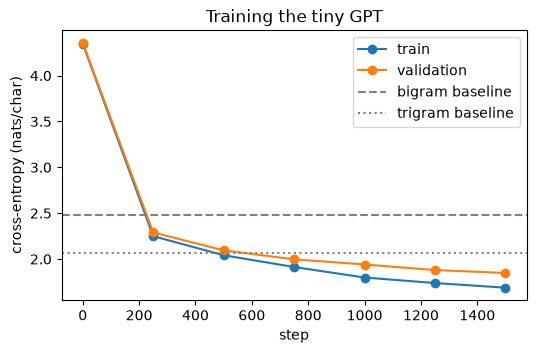

In [24]:
steps, tr, va = zip(*history)
plt.plot(steps, tr, "o-", label="train"); plt.plot(steps, va, "o-", label="validation")
plt.axhline(bigram_loss, color="gray", ls="--", label="bigram baseline")
plt.axhline(trigram_loss, color="gray", ls=":", label="trigram baseline")
plt.xlabel("step"); plt.ylabel("cross-entropy (nats/char)"); plt.legend(); plt.title("Training the tiny GPT"); plt.show()

### What did it learn to look at?

The attention matrices of a trained model are interpretable. Here is the first layer's heads on a short passage.

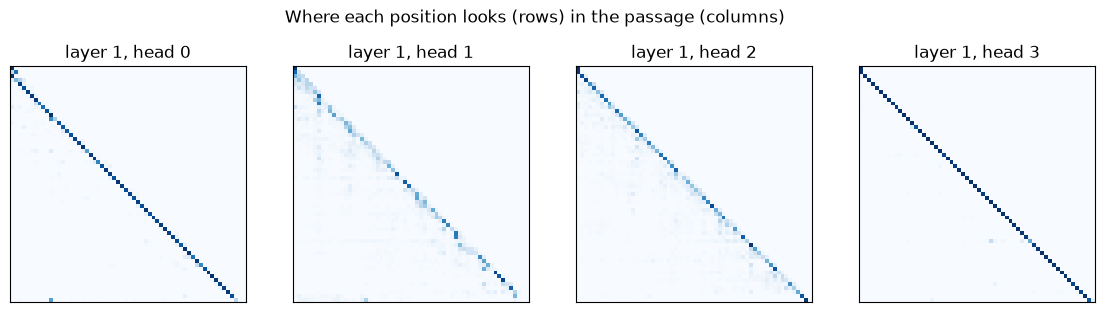

Typical patterns: a bright diagonal just below the main one (look at the previous character),
vertical stripes (everyone looks at a space or newline), and a broad lower triangle (average of the past).


In [25]:
passage = "First Citizen:\nBefore we proceed any further, hear me speak."
ids = torch.tensor([encode(passage)])
with torch.no_grad():
    x = model.tok_emb(ids) + model.pos_emb(torch.arange(ids.shape[1]))
    _, A = model.blocks[0].attention(model.blocks[0].ln1(x))
A = A[0].numpy()                                      # (n_head, n, n)
fig, axes = plt.subplots(1, n_head, figsize=(14, 3.6))
for h, ax in enumerate(axes):
    ax.imshow(A[h], cmap="Blues"); ax.set_title(f"layer 1, head {h}")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Where each position looks (rows) in the passage (columns)"); plt.show()
print("Typical patterns: a bright diagonal just below the main one (look at the previous character),\n"
      "vertical stripes (everyone looks at a space or newline), and a broad lower triangle (average of the past).")

### Longer samples

Lower `temperature` makes the model pick its most likely characters, which reads as more conservative; higher makes it more adventurous.

In [26]:
for temp in [0.7, 1.0]:
    print(f"=== temperature {temp} ===")
    print(decode(model.generate(torch.tensor([encode("\n")]), 500, temperature=temp)[0]))
    print()

=== temperature 0.7 ===

I wanto that bet a prepaint to gentlems and maints. I nevery.

LARET:
But the would had son, where comfassing him,
In but the me too full me ranger in a parted upon shall and as the cannot part
The faultient beluners to live the earth:
For the part this death of runt shall the stay be of
Count me as as brooke in king danief mady cause, her fall.

COMIO:
Therefore the seecerning puty my fatter brother.

GLOUCESTER:
Thereof the waith! whith you Rart the the cause miney!

POMEONTER:
Now, I she thou

=== temperature 1.0 ===

Citizan of it, I all ssiney theinice?

DOMPEY:
Outters as of I had, his wise it i' men hath a bloin'd a cap true.

There:
I more braidits are 'twas as loathy, her,
I'll of be do oose, thou reath; and whilusent,
he bouth togs'd all mairs, Papperners of Romeo his tiels,
I'll thy mays tribles of full, and than note beent
Scament the beinks go paintern, and failone, and your all the mart.

LADY CAMILLO:
And ye a more and sard thee as faold hath tal

### Exercises

**Exercise 5.1.** Train for the same number of steps with the position embedding disabled (`self.pos_emb` returning zeros). How much worse is the validation loss? Look at the samples: what kind of structure is missing?

**Exercise 5.2.** Change `block_size` to 8 and to 128, retraining each time. Plot validation loss against context length. Why does a longer context help, and why does the gain flatten out for a model this small?

**Exercise 5.3.** Replace `input.txt` with a Danish text (for example a collection of Andersen's fairy tales as plain UTF-8). Nothing in the code depends on the language. What changes in the vocabulary, and does the model learn Danish spelling patterns (æ, ø, å placement; -ede endings)?

**Exercise 5.4.** The model has about 100 000 parameters and trained for a few minutes. GPT-2 (2019) had 1.5 billion, and current models are thousands of times larger still, trained on terabytes of text, with the same architecture. Look at the loss curve: it is still going down when we stopped. What would you expect from training 10× longer? 10× bigger? (Then try 10× longer, if you have the time.)

In [27]:
# Solution 5.1
class GPTNoPos(GPT):
    def forward(self, ids):
        B, n = ids.shape
        x = self.tok_emb(ids)                     # no "+ pos_emb"
        for blk in self.blocks: x = blk(x)
        return self.head(self.ln_f(x))

torch.manual_seed(0)
model_np = GPTNoPos(vocab_size, block_size, n_embd, n_head, n_layer)
opt = torch.optim.AdamW(model_np.parameters(), lr=3e-3)
for step in range(1500):
    xb, yb = get_batch("train")
    loss = F.cross_entropy(model_np(xb).transpose(1, 2), yb)
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    val_np = float(np.mean([F.cross_entropy(model_np(x).transpose(1, 2), y).item() for x, y in (get_batch("val") for _ in range(20))]))
print(f"validation loss without positions: {val_np:.3f}   with positions: {history[-1][2]:.3f}")
print(decode(model_np.generate(torch.tensor([encode("\n")]), 300)[0]))
# Without positions the model can only use the SET of previous characters, not their
# order. It still learns letter frequencies and roughly which letters co-occur, but
# word-internal order (and thus spelling) degrades, and it cannot tell which
# character is the most recent one, which is the single most informative fact.

validation loss without positions: 2.195   with positions: 1.848

RTo menon the thysicfaie n, whit Ray ul the?

MIThy the ERETER: gold:
Tor ntlan at fllabosst:
Is, y bplive ama man n,
Who ad'de carshar dyomst, hull tover rvowie ordo;
Wiced t higar this whyour nde.

ABRTHerepows w Jureyou, ak---whisive!


IAR chose thers sheat ich VIUS fenscarbior.

Hesur, mor, Le 


block_size   8: validation loss 2.172
block_size  32: validation loss 1.969
block_size 128: validation loss 1.953


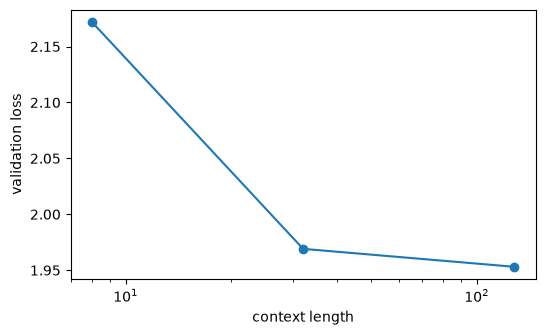

In [28]:
# Solution 5.2
results = {}
for bs in [8, 32, 128]:
    torch.manual_seed(0)
    m = GPT(vocab_size, bs, n_embd, n_head, n_layer)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
    for step in range(1000):
        ix = torch.randint(len(train_t) - bs - 1, (32,))
        xb = torch.stack([train_t[i:i+bs] for i in ix]); yb = torch.stack([train_t[i+1:i+bs+1] for i in ix])
        loss = F.cross_entropy(m(xb).transpose(1, 2), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        ix = torch.randint(len(val_t) - bs - 1, (256,))
        xb = torch.stack([val_t[i:i+bs] for i in ix]); yb = torch.stack([val_t[i+1:i+bs+1] for i in ix])
        results[bs] = F.cross_entropy(m(xb).transpose(1, 2), yb).item()
    print(f"block_size {bs:3d}: validation loss {results[bs]:.3f}")
plt.plot(list(results), list(results.values()), "o-"); plt.xscale("log")
plt.xlabel("context length"); plt.ylabel("validation loss"); plt.show()
# Longer context lets the model finish words it has seen the start of and keep
# track of line structure. Beyond a few dozen characters a 100k-parameter model
# has no capacity left to exploit the extra context, so the curve flattens.
# (Note the loss is averaged over all positions, and early positions in a window
# have little context regardless of block_size, which also dampens the effect.)

## Summary

- A language model is a classifier over "next character" whose input is the previous characters. Same loss, same gradient, same optimiser as the digits network.
- **Attention** is a learned weighted average over earlier positions. The weights come from dot products between queries and keys; a causal mask hides the future; values carry the content.
- A **GPT** is attention plus the digits network (the MLP), plus residual connections, layer norm and position embeddings, stacked.
- The forward pass is short enough to write in NumPy. The backward pass is the same chain rule, but the bookkeeping is why **autograd** exists; we verified that it reproduces our hand-derived gradients before trusting it.
- With 100 000 parameters and a few minutes on a CPU, the model goes from noise to text with real words, punctuation and dialogue structure. Everything beyond that is scale.